# Lab 4 — IoT Hydroponics / Microgreens
## Mismo código de Lab3/redFFBP
**Predicción:** conductividad eléctrica (EC).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
base=Path.cwd()
zp=base.parent/"datasets"/"28667981.zip" if base.name=="notebooks" else base/"datasets"/"28667981.zip"
out=zp.parent/"iot"
out.mkdir(exist_ok=True)
with zipfile.ZipFile(zp) as z: z.extractall(out)
archivos=sorted(out.glob("sensor_data_*.csv"))
df=pd.concat([pd.read_csv(x) for x in archivos],ignore_index=True)
print(df.head())
print("Registros:",len(df))
print("Faltantes:\n",df.isna().sum())

             timestamp  temperature  humidity   light    pH  \
0  2025-03-01 00:00:00        24.69     52.66  118.65  6.68   
1  2025-03-01 00:00:05        21.89     50.18  801.71  7.29   
2  2025-03-01 00:00:10        23.88     48.01  682.39  7.66   
3  2025-03-01 00:00:15        20.42     56.73  146.05  7.77   
4  2025-03-01 00:00:20        20.79     41.54  106.87  7.77   

   electrical_conductivity  
0                    0.996  
1                    1.044  
2                    1.354  
3                    0.519  
4                    1.900  
Registros: 120960
Faltantes:
 timestamp                  0
temperature                0
humidity                   0
light                      0
pH                         0
electrical_conductivity    0
dtype: int64


electrical_conductivity    1.000000
temperature                0.003117
pH                         0.001322
light                     -0.001242
humidity                  -0.001568
Name: electrical_conductivity, dtype: float64


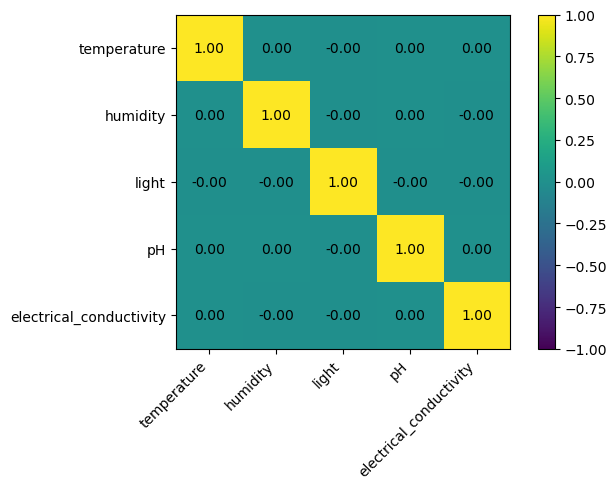

In [3]:
cols=['temperature', 'humidity', 'light', 'pH', 'electrical_conductivity']
corr=df[cols].corr()
print(corr['electrical_conductivity'].sort_values(ascending=False))

fig,ax=plt.subplots(figsize=(7,5))
im=ax.imshow(corr,vmin=-1,vmax=1)
ax.set_xticks(range(len(cols)),cols,rotation=45,ha="right")
ax.set_yticks(range(len(cols)),cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im)
plt.tight_layout()
plt.show()

In [4]:
X = df[['temperature', 'humidity', 'light', 'pH']].values
y = df[['electrical_conductivity']].values

# 60% entrenamiento / 40% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.40, random_state=42
)

# Nuevo en Lab4: normalizacion para datos reales
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)
y_train_norm = scaler_y.fit_transform(y_train)
y_test_norm = scaler_y.transform(y_test)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))

Entrenamiento: 72576
Prueba: 48384


In [8]:
# MISMA IMPLEMENTACION DE Lab3/redFFBP
def ReLu(x):
    return np.maximum(0, x)

class Capa:
    def __init__(self, entradas, neuronas, activacion=None, bias=False):
        self.entradas = entradas
        self.neuronas = neuronas
        self.activacion = activacion
        self.bias = bias

        self.pesos = np.random.randn(entradas, neuronas) * 0.1

        if bias:
            self.b = np.zeros((1, neuronas))
        else:
            self.b = None

    def feed_forward(self, X):
        self.entrada = X
        self.z = X @ self.pesos

        if self.bias:
            self.z += self.b

        if self.activacion is not None:
            self.salida = self.activacion(self.z)
        else:
            self.salida = self.z

        return self.salida

    def backward(self, ultima=False, error=None,
                 delta_siguiente=None, pesos_siguientes=None):

        if ultima:
            self.delta = error
        else:
            self.delta = delta_siguiente @ pesos_siguientes.T

            if self.activacion == ReLu:
                self.delta *= (self.z > 0)

        self.grad_pesos = self.entrada.T @ self.delta

        if self.bias:
            self.grad_bias = np.sum(
                self.delta,
                axis=0,
                keepdims=True
            )

        return self.delta

In [9]:
np.random.seed(42)

capa1 = Capa(
    entradas=4,
    neuronas=13,
    activacion=ReLu,
    bias=True
)

capa2 = Capa(
    entradas=13,
    neuronas=1,
    activacion=None,
    bias=True
)

epocas = 1000

alpha = 0.01 / len(X_train)

historial_perdida = []

for epoca in range(epocas):

    # Feed Forward
    salida1 = capa1.feed_forward(X_train)
    resultado = capa2.feed_forward(salida1)

    # Error
    error = resultado - y_train_norm

    # Perdida
    perdida = 0.5 * np.mean(error ** 2)
    historial_perdida.append(perdida)

    # Backpropagation
    delta2 = capa2.backward(
        ultima=True,
        error=error
    )

    delta1 = capa1.backward(
        ultima=False,
        delta_siguiente=delta2,
        pesos_siguientes=capa2.pesos
    )

    # Actualizacion de pesos
    capa1.pesos -= alpha * capa1.grad_pesos
    capa2.pesos -= alpha * capa2.grad_pesos

    # Actualizacion de bias
    capa1.b -= alpha * capa1.grad_bias
    capa2.b -= alpha * capa2.grad_bias

    if epoca == 0 or (epoca + 1) % 50 == 0:
        print("Epoca:", epoca + 1, "- Perdida:", perdida)

# En TEST solo hacemos Feed Forward.
# NO se hace Backpropagation con los datos de prueba.
salida_test = capa1.feed_forward(X_test)
pred_test_norm = capa2.feed_forward(salida_test)

pred_test = scaler_y.inverse_transform(pred_test_norm)
y_test_real = scaler_y.inverse_transform(y_test_norm)

Epoca: 1 - Perdida: 0.5003979736716785
Epoca: 50 - Perdida: 0.5003722725438954
Epoca: 100 - Perdida: 0.5003529286564047
Epoca: 150 - Perdida: 0.5003365127980031
Epoca: 200 - Perdida: 0.5003215904201319
Epoca: 250 - Perdida: 0.5003077123303115
Epoca: 300 - Perdida: 0.5002947137065432
Epoca: 350 - Perdida: 0.5002824010278185
Epoca: 400 - Perdida: 0.5002707030061113
Epoca: 450 - Perdida: 0.5002595739655258
Epoca: 500 - Perdida: 0.500248959252705
Epoca: 550 - Perdida: 0.5002387806700739
Epoca: 600 - Perdida: 0.50022910787164
Epoca: 650 - Perdida: 0.500219933759033
Epoca: 700 - Perdida: 0.5002111637928873
Epoca: 750 - Perdida: 0.5002027843363496
Epoca: 800 - Perdida: 0.5001947686178169
Epoca: 850 - Perdida: 0.5001871687100281
Epoca: 900 - Perdida: 0.5001799093773193
Epoca: 950 - Perdida: 0.5001729314243584
Epoca: 1000 - Perdida: 0.5001661800996973


R² = -0.0005720806991986738
R = -0.0016321574171760567
MAE = 0.37621835856446606
RMSE = 0.434381471849189


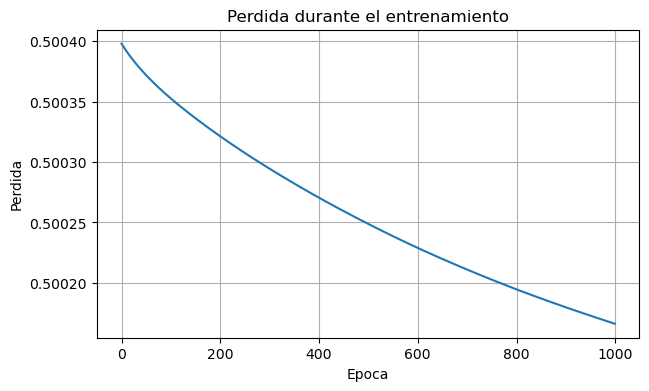

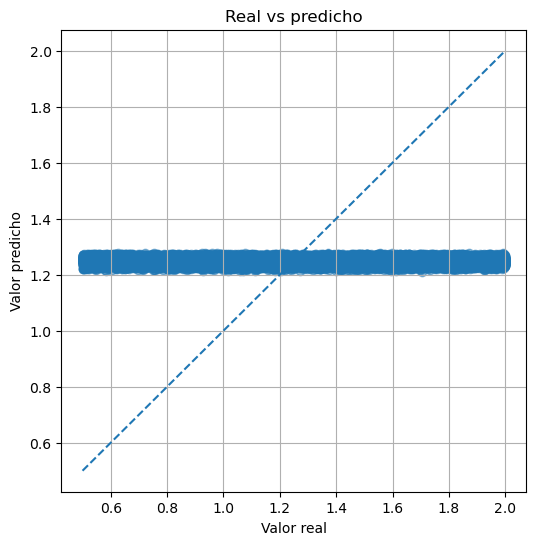

In [10]:
r2 = r2_score(y_test_real, pred_test)
r = np.corrcoef(y_test_real.ravel(), pred_test.ravel())[0, 1]
mae = mean_absolute_error(y_test_real, pred_test)
rmse = np.sqrt(mean_squared_error(y_test_real, pred_test))

print("R² =", r2)
print("R =", r)
print("MAE =", mae)
print("RMSE =", rmse)

plt.figure(figsize=(7,4))
plt.plot(historial_perdida)
plt.xlabel("Epoca")
plt.ylabel("Perdida")
plt.title("Perdida durante el entrenamiento")
plt.grid()
plt.show()

plt.figure(figsize=(6,6))
plt.scatter(y_test_real, pred_test, alpha=0.5)
a=min(y_test_real.min(),pred_test.min())
b=max(y_test_real.max(),pred_test.max())
plt.plot([a,b],[a,b],"--")
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Real vs predicho")
plt.grid()
plt.show()